# Chapitre 11 - Exercices 11.1 à 11.6

Ce notebook traite les six premiers exercices du chapitre 11, centrés sur le transport
des flux et le lien entre bases de données et flux :

- **11.1** : sondage contre notification, qui coûte le moins cher ? (calcul et simulation) ;
- **11.2** : dimensionner les partitions d'un sujet, clés chaudes et changement du
  nombre de partitions (calcul et mini-lab) ;
- **11.3** : rétention, consommateur en panne et rattrapage (calcul) ;
- **11.4** : fréquence de validation des offsets et doublons (calcul et simulation) ;
- **11.5** : trouver l'anomalie d'un cache invalidé par double écriture (raisonnement
  et simulation) ;
- **11.6** : taille d'un sujet compacté (calcul et mini-lab).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 11.1 : sondage contre notification

**Énoncé.** 2 000 consommateurs veulent tous être informés des nouvelles lignes d'une
table `evenements`. Deux régimes de trafic : calme (0,1 événement par seconde) et chargé
(50 événements par seconde), arrivées de Poisson.

1. En sondage (polling) toutes les $T = 0{,}5$ s, combien de requêtes par seconde la base
   reçoit-elle ? Quelle fraction revient vide dans chaque régime ? Quel délai moyen
   avant qu'un événement soit vu ?
2. Avec un courtier qui pousse chaque événement à chaque consommateur (diffusion), combien
   de messages par seconde faut-il livrer dans chaque régime ?
3. Conclure : quand le sondage est-il plus économe que la notification ? Quel mécanisme
   simple rend le sondage acceptable quand le trafic est chargé ?
4. Vérifier les fractions vides et le délai par simulation.

**Rappels.** Interrogations vides avec probabilité $e^{-\lambda T}$, délai moyen $T/2$,
charge $n/T$ requêtes par seconde (cours 1, section 1, section *Transmitting Event
Streams*) ; diffusion à tous les consommateurs (cours 1, section 5, section *Multiple
consumers*).

**Solution.**

*1.* $n/T = 2\,000 / 0{,}5 = 4\,000$ requêtes par seconde, **quel que soit le trafic**.
Fraction vide : $e^{-0{,}1 \times 0{,}5} = e^{-0{,}05} \approx 95\,\%$ en régime calme,
$e^{-25} \approx 0$ en régime chargé. Délai moyen : $T/2 = 0{,}25$ s dans les deux cas.

*2.* Diffusion : $\lambda n$ livraisons par seconde, soit $0{,}1 \times 2\,000 = 200$ en
régime calme et $50 \times 2\,000 = 100\,000$ en régime chargé.

*3.* En régime calme, la notification fait 20 fois moins de travail (200 contre 4 000) :
la plupart des sondages sont inutiles. En régime chargé, c'est l'inverse : chaque sondage
rapporte en moyenne $\lambda T = 25$ événements d'un coup, donc 4 000 requêtes suffisent
là où la notification individuelle envoie 100 000 messages. Le seuil est
$\lambda n = n/T$, soit $\lambda T = 1$ : le sondage gagne quand il y a en moyenne plus
d'un événement par intervalle. Le remède côté notification est le **regroupement par
lots** (batching) : un consommateur de journal lit en une requête tous les messages
arrivés depuis son offset, ce qui combine l'absence de requêtes vides (il attend d'être
notifié, en « long polling ») et l'amortissement par lots.

**Vérification par simulation** : une heure d'événements de Poisson, un consommateur qui
sonde toutes les 0,5 s (les 2 000 consommateurs sont identiques).

In [2]:
T, n_cons, duree = 0.5, 2000, 3600
rows = []
for nom, lam in [("calme", 0.1), ("chargé", 50.0)]:
    t_ev = np.cumsum(rng.exponential(1 / lam, int(lam * duree * 1.2)))
    t_ev = t_ev[t_ev < duree]
    sondages = np.arange(T, duree + T, T)
    par_sondage = np.histogram(t_ev, bins=np.concatenate([[0], sondages]))[0]
    vu = np.ceil(t_ev / T) * T                               # prochain sondage après l'événement
    rows.append({"régime": nom, "requêtes/s (sondage)": n_cons / T, "vides (simulé)": (par_sondage == 0).mean(),
                 "vides (théorie)": math.exp(-lam * T), "délai moyen (s)": (vu - t_ev).mean(),
                 "livraisons/s (notification)": lam * n_cons, "événements par sondage": par_sondage.mean()})
pd.DataFrame(rows).set_index("régime")

,requêtes/s (sondage),vides (simulé),vides (théorie),délai moyen (s),livraisons/s (notification),événements par sondage
régime,,,,,,
calme,4000.0,0.957,9.512e-01,0.246,200.0,0.044
chargé,4000.0,0.000,1.389e-11,0.250,100000.0,25.071


Les fractions vides et le délai moyen de 0,25 s sont retrouvés. Le graphique situe le
seuil $\lambda T = 1$ pour 2 000 consommateurs.

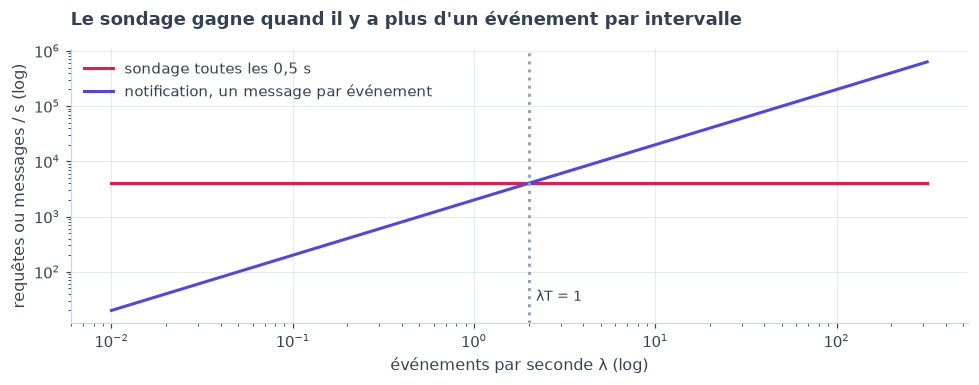

In [3]:
lams = np.logspace(-2, 2.5, 200)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(lams, np.full_like(lams, n_cons / T), color=ROSE, label="sondage toutes les 0,5 s")
ax.plot(lams, lams * n_cons, color=INDIGO, label="notification, un message par événement")
ax.axvline(1 / T, color=GRAY, ls=":")
ax.text(1 / T * 1.1, 30, "λT = 1", color=SLATE, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("événements par seconde λ (log)"); ax.set_ylabel("requêtes ou messages / s (log)")
ax.set_title("Le sondage gagne quand il y a plus d'un événement par intervalle")
ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Le sondage coûte $n/T$ quel que soit le trafic, la notification $\lambda n$ ;
> le seuil est $\lambda T = 1$. Les journaux combinent le meilleur des deux : notification
> (pas de requête vide) et lecture par lots (coût amorti).

## Exercice 11.2 : dimensionner les partitions d'un sujet

**Énoncé.** Un sujet reçoit en pointe 120 Mo/s de messages de 1 Ko, avec l'identifiant
de l'utilisateur comme clé. Une partition supporte au plus 10 Mo/s en écriture (limite
observée du disque et de la réplication) ; un consommateur traite 6 000 messages par
seconde.

1. Combien de partitions au minimum pour l'écriture ? Pour la consommation ? Combien de
   consommateurs au plus seront utiles dans un groupe ?
2. La popularité des utilisateurs suit une loi de Zipf ($s = 1{,}1$, 1 million
   d'utilisateurs). Avec 24 partitions et le partitionneur de Kafka (`st.kafka_partition`),
   quelle est la charge de la partition la plus chargée, rapportée à la moyenne ? Que
   faut-il en conclure pour le dimensionnement ?
3. Six mois plus tard, on passe de 24 à 32 partitions. Quelle fraction des clés change de
   partition ? Quelle garantie est perdue pendant la transition ?

**Rappels.** Une partition est lue par un seul consommateur du groupe ; l'ordre n'est
garanti que dans une partition ; la partition d'une clé est
$\text{murmur2}(\text{clé}) \bmod P$ (cours 2, sections 1 et 2, sections *Using logs for
message storage* et *Logs compared to traditional messaging* ; clés chaudes : chapitre
6).

**Solution.**

*1.* Écriture : $120 / 10 = 12$ partitions au minimum. Consommation : 120 Mo/s de
messages de 1 Ko font environ 123 000 messages par seconde (avec 1 Ko = 1 024 octets et
1 Mo = 1 048 576 octets, soit 122 880), donc $\lceil 122\,880 / 6\,000 \rceil = 21$
consommateurs, donc **au moins 21 partitions** (un consommateur par partition au plus).
Le nombre de consommateurs utiles est plafonné par le nombre de partitions.

*2.* Les clés ne sont pas également actives : une partition reçoit toutes les clés
chaudes que le hachage lui attribue. On le mesure ci-dessous. Il faut dimensionner pour
la **partition la plus chargée**, pas pour la moyenne : soit prévoir davantage de
partitions et de marge, soit traiter à part les clés les plus chaudes (par exemple en leur
ajoutant un suffixe aléatoire, au prix de l'ordre entre leurs messages).

*3.* Avec un partitionnement par $\bmod P$, une clé ne reste en place que si
$h \bmod 24 = h \bmod 32$. Ces deux restes ne dépendent que de $r = h \bmod 96$
(96 est le PPCM de 24 et 32) ; en passant en revue les 96 valeurs de $r$, l'égalité n'a
lieu que pour $r < 24$. Un quart des clés reste en place, **trois quarts changent de
partition**. Pendant la transition, les anciens messages d'une clé sont dans l'ancienne
partition et les nouveaux dans une autre : **l'ordre par clé n'est plus garanti** (un
consommateur peut lire un message récent avant un ancien).

partitions minimales : écriture 12, consommation 21
partition la plus chargée : 3.50 × la moyenne ; la clé la plus chaude seule pèse 12.4% du trafic (2.97 × une partition moyenne)
clés qui changent de partition (24 -> 32) : 75.0%


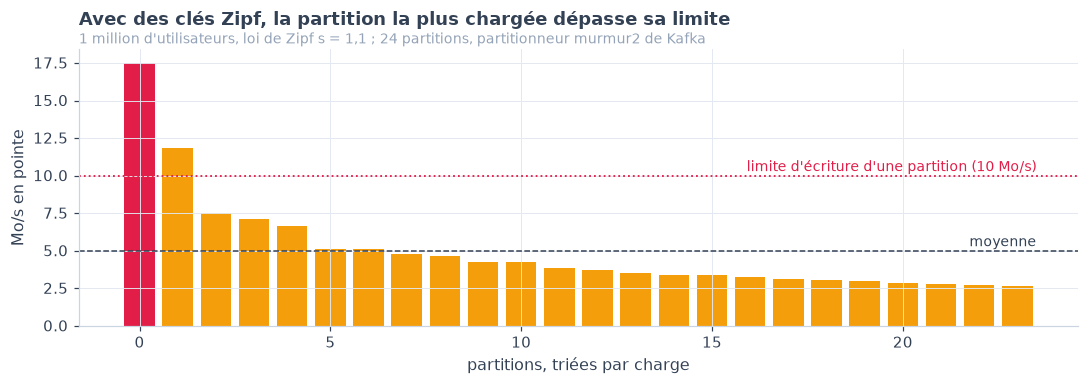

In [4]:
n_users, P = 1_000_000, 24
poids = 1 / np.arange(1, n_users + 1) ** 1.1
poids /= poids.sum()
cles = [f"user-{i}" for i in range(n_users)]
part24 = np.array([st.kafka_partition(k, 24) for k in cles])
part32 = np.array([st.kafka_partition(k, 32) for k in cles])
charge = np.bincount(part24, weights=poids, minlength=24)
print(f"partitions minimales : écriture {math.ceil(120 / 10)}, consommation {math.ceil(120 * 1024 / 6000)}")
print(f"partition la plus chargée : {charge.max() / charge.mean():.2f} × la moyenne ; "
      f"la clé la plus chaude seule pèse {poids[0]:.1%} du trafic ({poids[0] * 24:.2f} × une partition moyenne)")
print(f"clés qui changent de partition (24 -> 32) : {(part24 != part32).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 3.6))
ordre = np.argsort(-charge)
ax.bar(range(24), charge[ordre] * 120, color=[ROSE if i == 0 else AMBER for i in range(24)])
ax.axhline(120 / 24, color=SLATE, ls="--", lw=1)
ax.axhline(10, color=ROSE, ls=":", lw=1.2)
ax.text(23.5, 10.3, "limite d'écriture d'une partition (10 Mo/s)", ha="right", color=ROSE, fontsize=9)
ax.text(23.5, 120 / 24 + 0.3, "moyenne", ha="right", color=SLATE, fontsize=9)
ax.set_xlabel("partitions, triées par charge"); ax.set_ylabel("Mo/s en pointe")
ax.set_title("Avec des clés Zipf, la partition la plus chargée dépasse sa limite")
subtitle(ax, "1 million d'utilisateurs, loi de Zipf s = 1,1 ; 24 partitions, partitionneur murmur2 de Kafka")
plt.tight_layout(); plt.show()

La partition qui hérite de la clé la plus chaude reçoit 3,5 fois la charge moyenne et
dépasse largement la limite de 10 Mo/s (une deuxième partition la dépasse aussi), alors que la moyenne (5 Mo/s) laisse une marge
confortable. Ajouter des partitions ne résout rien pour cette clé : une clé ne se
partage pas. Et changer le nombre de partitions déplace les trois quarts des clés,
comme prévu : c'est pourquoi on surdimensionne le nombre de partitions dès
la création d'un sujet.

> **À retenir.** Dimensionner un sujet : $\max(\text{débit} / \text{débit par partition},
> \text{messages/s} / \text{capacité d'un consommateur})$ partitions, plus une marge pour la
> partition la plus chargée ; les clés chaudes ne se divisent pas, et changer le nombre
> de partitions casse l'ordre par clé.